# data analyzer

YOLO DATASET ANALYSIS
Dataset: FYP_MOCSdataset.v3i.yolo26_bbox
Path:    C:\Users\Ева\Desktop\Хакатон\data_preproc\datasets\FYP_MOCSdataset.v3i.yolo26_bbox
YAML:    C:\Users\Ева\Desktop\Хакатон\data_preproc\datasets\FYP_MOCSdataset.v3i.yolo26_bbox\data.yaml
Output:  dataset_info\FYP_MOCSdataset.v3i.yolo26_bbox

Classes from data.yaml:
  0: Bulldozer
  1: Concrete mixer
  2: Crane
  3: Excavator
  4: Hanging head
  5: Loader
  6: Other vehicle
  7: Pile driving
  8: Pump truck
  9: Roller
  10: Static crane
  11: Truck
  12: Worker

Images found: 9238
Labels found: 9238



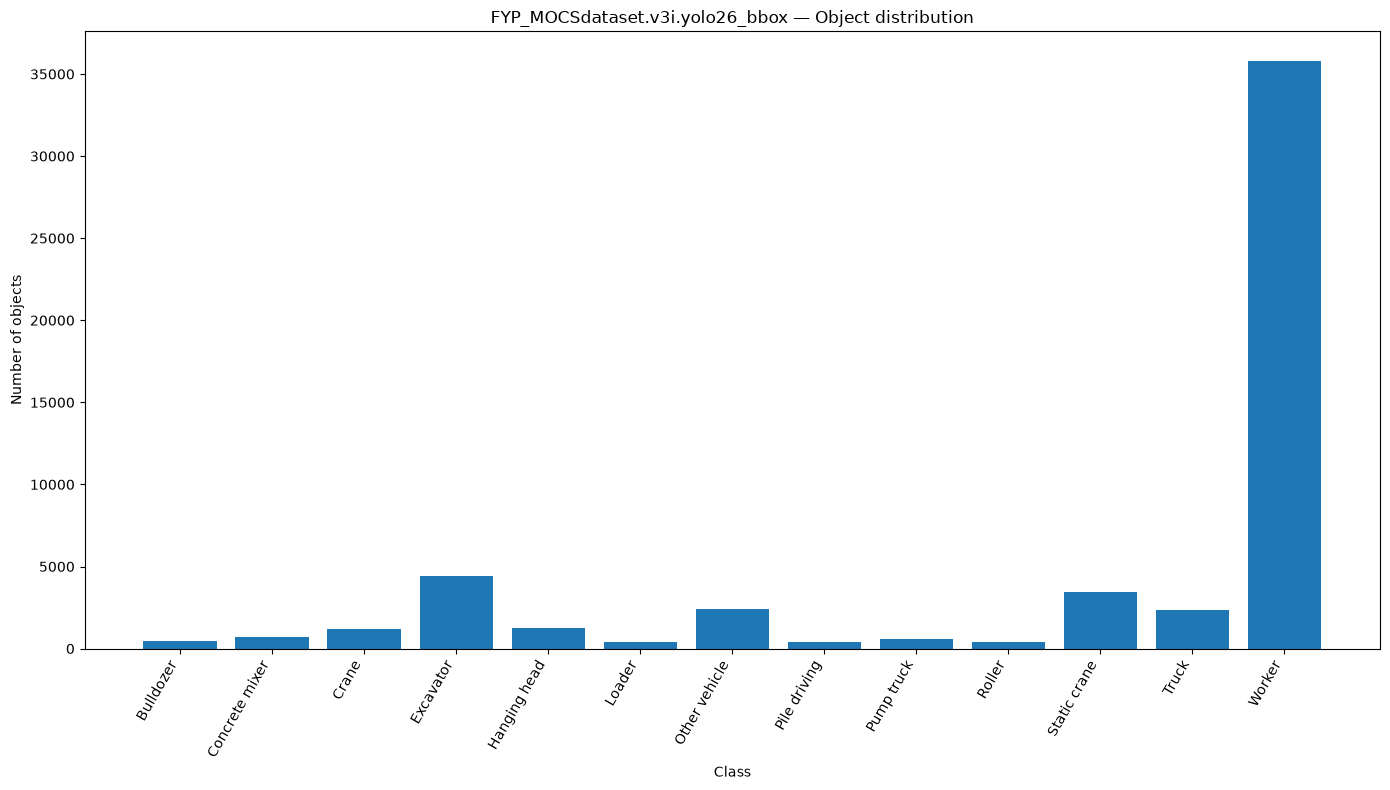

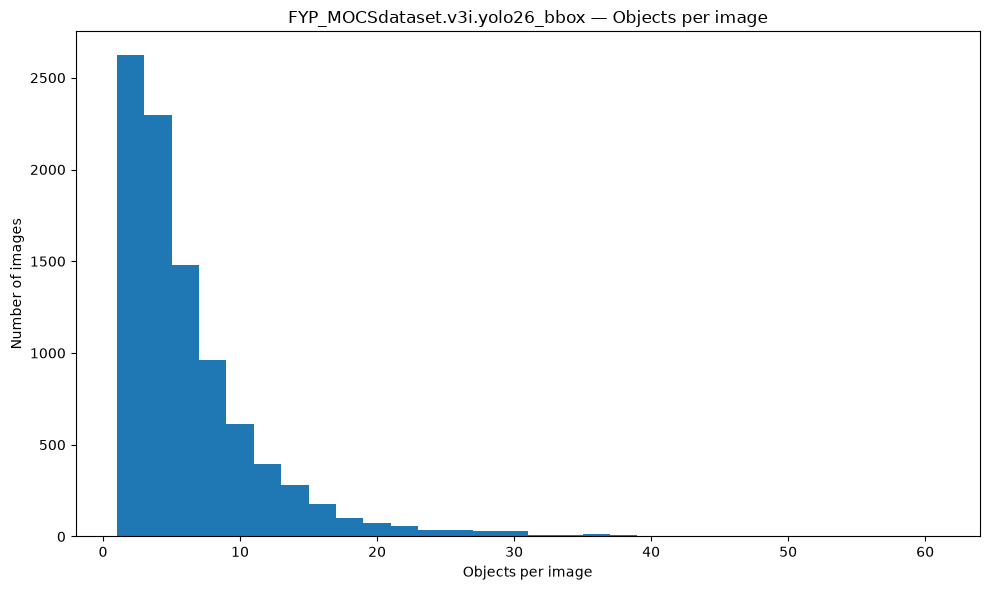

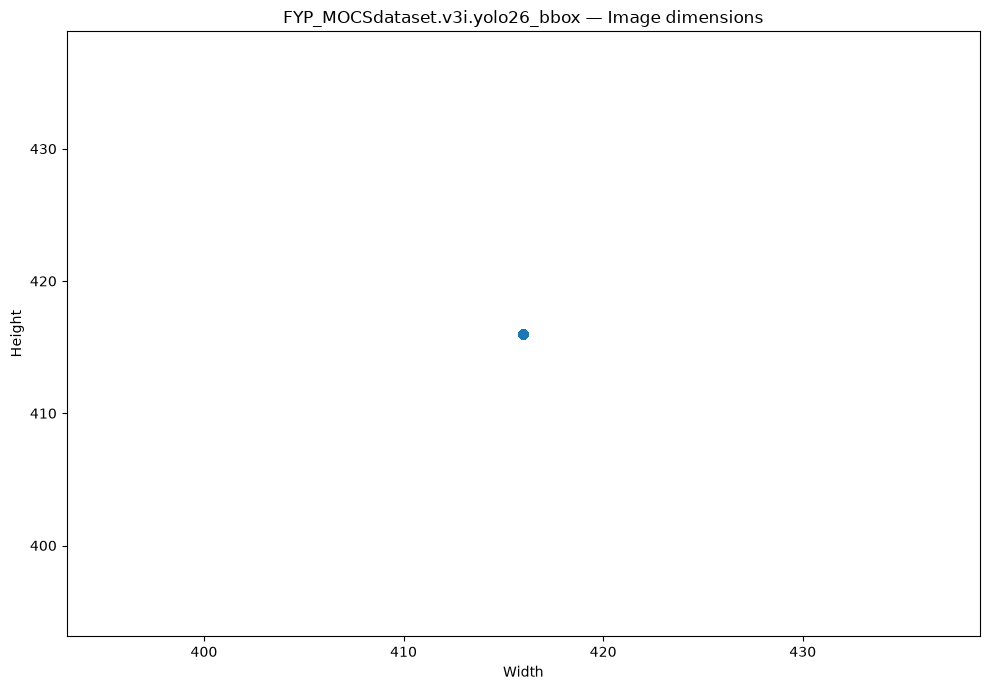

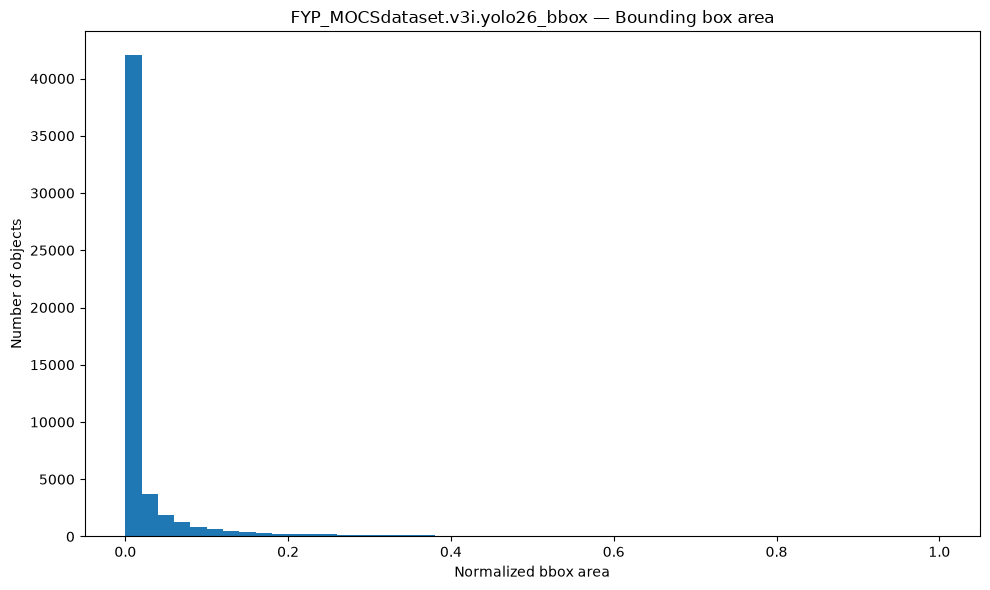


ANALYSIS FINISHED

Dataset:          FYP_MOCSdataset.v3i.yolo26_bbox
Images:           9238
Objects:          53958
Classes defined:  13
Classes present:  13
Mean obj/image:   5.84

Output directory:
C:\Users\Ева\Desktop\Хакатон\data_preproc\dataset_info\FYP_MOCSdataset.v3i.yolo26_bbox

Examples:
C:\Users\Ева\Desktop\Хакатон\data_preproc\dataset_info\FYP_MOCSdataset.v3i.yolo26_bbox\examples

Master dataset CSV:
C:\Users\Ева\Desktop\Хакатон\data_preproc\dataset_info\all_datasets_summary.csv


In [1]:
from pathlib import Path
from collections import Counter
import random
import yaml

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont


# ============================================================
# 1. CONFIGURATION
# ============================================================

# Путь к ОДНОМУ датасету
DATASET_PATH = Path(
    r"C:\Users\Ева\Desktop\Хакатон\data_preproc\datasets\FYP_MOCSdataset.v3i.yolo26_bbox"
)

# Общая папка для результатов всех датасетов
INFO_ROOT = Path("dataset_info")

# Количество случайных изображений для визуализации
N_EXAMPLES = 5

# Seed для воспроизводимого выбора
RANDOM_SEED = 42


# ============================================================
# 2. READ CLASSES FROM data.yaml
# ============================================================

DATA_YAML = DATASET_PATH / "data.yaml"

if not DATA_YAML.exists():

    # На случай, если файл называется dataset.yaml
    DATA_YAML = DATASET_PATH / "dataset.yaml"


if not DATA_YAML.exists():

    raise FileNotFoundError(
        f"Не найден data.yaml или dataset.yaml:\n"
        f"{DATASET_PATH}"
    )


with open(
    DATA_YAML,
    "r",
    encoding="utf-8"
) as f:

    yaml_data = yaml.safe_load(f)


# ------------------------------------------------------------
# Получаем names
# ------------------------------------------------------------

if "names" not in yaml_data:

    raise ValueError(
        f"В файле {DATA_YAML} отсутствует параметр 'names'"
    )


names_from_yaml = yaml_data["names"]


# ------------------------------------------------------------
# names может быть:
#
# names:
#   - Bulldozer
#   - Concrete mixer
#
# или:
#
# names:
#   0: Bulldozer
#   1: Concrete mixer
# ------------------------------------------------------------

if isinstance(names_from_yaml, list):

    CLASS_NAMES = {
        class_id: class_name
        for class_id, class_name
        in enumerate(names_from_yaml)
    }

elif isinstance(names_from_yaml, dict):

    CLASS_NAMES = {
        int(class_id): class_name
        for class_id, class_name
        in names_from_yaml.items()
    }

else:

    raise ValueError(
        "Неверный формат 'names' в data.yaml"
    )


# ============================================================
# 3. OUTPUT DIRECTORIES
# ============================================================

dataset_name = DATASET_PATH.name

OUTPUT_DIR = (
    INFO_ROOT /
    dataset_name
)

EXAMPLES_DIR = (
    OUTPUT_DIR /
    "examples"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EXAMPLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 4. START
# ============================================================

print("=" * 70)
print("YOLO DATASET ANALYSIS")
print("=" * 70)

print(f"Dataset: {dataset_name}")
print(f"Path:    {DATASET_PATH}")
print(f"YAML:    {DATA_YAML}")
print(f"Output:  {OUTPUT_DIR}")
print()

print("Classes from data.yaml:")

for class_id, class_name in CLASS_NAMES.items():

    print(
        f"  {class_id}: {class_name}"
    )

print()


# ============================================================
# 5. FIND IMAGES AND LABELS
# ============================================================

# ВАЖНО:
# Игнорируем train / val / test из data.yaml.
#
# Используем твою фактическую структуру:
#
# dataset/
# ├── images/
# ├── labels/
# └── data.yaml

IMAGES_DIR = (
    DATASET_PATH /
    "images"
)

LABELS_DIR = (
    DATASET_PATH /
    "labels"
)


if not IMAGES_DIR.exists():

    raise FileNotFoundError(
        f"Не найдена папка images:\n"
        f"{IMAGES_DIR}"
    )


if not LABELS_DIR.exists():

    raise FileNotFoundError(
        f"Не найдена папка labels:\n"
        f"{LABELS_DIR}"
    )


IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp",
    ".tif",
    ".tiff",
}


image_files = sorted(
    [
        p
        for p in IMAGES_DIR.rglob("*")
        if (
            p.is_file()
            and
            p.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    ]
)


label_files = sorted(
    [
        p
        for p in LABELS_DIR.rglob("*.txt")
        if p.is_file()
    ]
)


print(
    f"Images found: {len(image_files)}"
)

print(
    f"Labels found: {len(label_files)}"
)

print()


# ============================================================
# 6. DATA STRUCTURES
# ============================================================

class_object_counts = Counter()

class_image_counts = Counter()

objects_per_image = []

bbox_widths = []
bbox_heights = []
bbox_areas = []

image_widths = []
image_heights = []

images_without_labels = []
empty_label_files = []
invalid_label_lines = []
unknown_classes = []

image_records = []

all_annotations = []


# ============================================================
# 7. PROCESS IMAGES
# ============================================================

for image_path in image_files:

    relative_path = (
        image_path.relative_to(
            IMAGES_DIR
        )
    )

    # --------------------------------------------------------
    # LABEL PATH
    # --------------------------------------------------------

    label_path = (
        LABELS_DIR /
        relative_path.with_suffix(".txt")
    )


    # --------------------------------------------------------
    # IMAGE INFORMATION
    # --------------------------------------------------------

    try:

        with Image.open(image_path) as img:

            width, height = img.size

    except Exception:

        print(
            f"WARNING: cannot read image:\n"
            f"{image_path}"
        )

        continue


    image_widths.append(width)
    image_heights.append(height)


    # --------------------------------------------------------
    # LABEL INFORMATION
    # --------------------------------------------------------

    image_class_set = set()

    image_object_count = 0


    if not label_path.exists():

        images_without_labels.append(
            str(relative_path)
        )

    else:

        with open(
            label_path,
            "r",
            encoding="utf-8"
        ) as f:

            lines = [
                line.strip()
                for line in f
                if line.strip()
            ]


        if len(lines) == 0:

            empty_label_files.append(
                str(relative_path)
            )


        for line_number, line in enumerate(
            lines,
            start=1
        ):

            parts = line.split()


            # ------------------------------------------------
            # CHECK FORMAT
            # ------------------------------------------------

            if len(parts) != 5:

                invalid_label_lines.append({

                    "image": str(relative_path),

                    "line": line_number,

                    "content": line,

                    "reason": "Expected 5 values"

                })

                continue


            try:

                class_id = int(parts[0])

                x_center = float(parts[1])

                y_center = float(parts[2])

                box_width = float(parts[3])

                box_height = float(parts[4])


            except ValueError:

                invalid_label_lines.append({

                    "image": str(relative_path),

                    "line": line_number,

                    "content": line,

                    "reason": "Cannot parse numbers"

                })

                continue


            # ------------------------------------------------
            # CHECK CLASS
            # ------------------------------------------------

            if class_id not in CLASS_NAMES:

                unknown_classes.append({

                    "image": str(relative_path),

                    "class_id": class_id

                })

            else:

                class_object_counts[
                    class_id
                ] += 1

                image_class_set.add(
                    class_id
                )


            image_object_count += 1


            # ------------------------------------------------
            # BBOX STATISTICS
            # ------------------------------------------------

            bbox_widths.append(
                box_width
            )

            bbox_heights.append(
                box_height
            )


            bbox_area = (
                box_width *
                box_height
            )

            bbox_areas.append(
                bbox_area
            )


            all_annotations.append({

                "image":
                    str(relative_path),

                "class_id":
                    class_id,

                "class_name":
                    CLASS_NAMES.get(
                        class_id,
                        f"Unknown_{class_id}"
                    ),

                "x_center":
                    x_center,

                "y_center":
                    y_center,

                "width":
                    box_width,

                "height":
                    box_height,

                "area":
                    bbox_area,

            })


    # --------------------------------------------------------
    # CLASS IMAGE COUNTS
    # --------------------------------------------------------

    for class_id in image_class_set:

        class_image_counts[
            class_id
        ] += 1


    objects_per_image.append(
        image_object_count
    )


    image_records.append({

        "image":
            str(relative_path),

        "width":
            width,

        "height":
            height,

        "objects":
            image_object_count,

        "classes":
            len(image_class_set),

    })


# ============================================================
# 8. CLASS STATISTICS
# ============================================================

total_images = len(
    image_records
)

total_objects = sum(
    class_object_counts.values()
)


class_rows = []


for class_id, class_name in CLASS_NAMES.items():

    object_count = (
        class_object_counts.get(
            class_id,
            0
        )
    )

    image_count = (
        class_image_counts.get(
            class_id,
            0
        )
    )


    object_percentage = (

        object_count /
        total_objects *
        100

        if total_objects > 0

        else 0

    )


    image_percentage = (

        image_count /
        total_images *
        100

        if total_images > 0

        else 0

    )


    class_rows.append({

        "class_id":
            class_id,

        "class_name":
            class_name,

        "objects":
            object_count,

        "object_percentage":
            object_percentage,

        "images":
            image_count,

        "image_percentage":
            image_percentage,

    })


class_df = pd.DataFrame(
    class_rows
)


# ============================================================
# 9. IMAGE STATISTICS
# ============================================================

image_df = pd.DataFrame(
    image_records
)


if len(image_df) > 0:

    image_df["aspect_ratio"] = (

        image_df["width"] /
        image_df["height"]

    )


    image_df["megapixels"] = (

        image_df["width"] *
        image_df["height"] /
        1_000_000

    )


# ============================================================
# 10. BBOX STATISTICS
# ============================================================

if bbox_widths:

    bbox_df = pd.DataFrame(
        all_annotations
    )


    bbox_statistics = {

        "total_bboxes":
            len(bbox_df),


        "mean_width_normalized":
            np.mean(bbox_widths),

        "median_width_normalized":
            np.median(bbox_widths),

        "min_width_normalized":
            np.min(bbox_widths),

        "max_width_normalized":
            np.max(bbox_widths),


        "mean_height_normalized":
            np.mean(bbox_heights),

        "median_height_normalized":
            np.median(bbox_heights),

        "min_height_normalized":
            np.min(bbox_heights),

        "max_height_normalized":
            np.max(bbox_heights),


        "mean_area_normalized":
            np.mean(bbox_areas),

        "median_area_normalized":
            np.median(bbox_areas),

        "min_area_normalized":
            np.min(bbox_areas),

        "max_area_normalized":
            np.max(bbox_areas),

    }


else:

    bbox_df = pd.DataFrame()

    bbox_statistics = {
        "total_bboxes": 0
    }


# ============================================================
# 11. DATASET SUMMARY
# ============================================================

summary = {

    "dataset":
        dataset_name,

    "images":
        total_images,

    "label_files":
        len(label_files),

    "total_objects":
        total_objects,

    "classes_defined":
        len(CLASS_NAMES),

    "classes_present":
        sum(
            1
            for class_id
            in CLASS_NAMES
            if (
                class_object_counts.get(
                    class_id,
                    0
                ) > 0
            )
        ),

    "images_without_labels":
        len(images_without_labels),

    "empty_label_files":
        len(empty_label_files),

    "invalid_label_lines":
        len(invalid_label_lines),

    "unknown_classes":
        len(unknown_classes),

    "mean_objects_per_image":
        (
            np.mean(objects_per_image)
            if objects_per_image
            else 0
        ),

    "median_objects_per_image":
        (
            np.median(objects_per_image)
            if objects_per_image
            else 0
        ),

    "min_objects_per_image":
        (
            np.min(objects_per_image)
            if objects_per_image
            else 0
        ),

    "max_objects_per_image":
        (
            np.max(objects_per_image)
            if objects_per_image
            else 0
        ),

    "mean_image_width":
        (
            np.mean(image_widths)
            if image_widths
            else 0
        ),

    "mean_image_height":
        (
            np.mean(image_heights)
            if image_heights
            else 0
        ),

    "median_image_width":
        (
            np.median(image_widths)
            if image_widths
            else 0
        ),

    "median_image_height":
        (
            np.median(image_heights)
            if image_heights
            else 0
        ),

}


summary.update(
    bbox_statistics
)


summary_df = pd.DataFrame(
    [summary]
)


# ============================================================
# 12. SAVE CSV
# ============================================================

summary_df.to_csv(
    OUTPUT_DIR /
    "dataset_summary.csv",

    index=False,

    encoding="utf-8-sig"
)


class_df.to_csv(
    OUTPUT_DIR /
    "class_distribution.csv",

    index=False,

    encoding="utf-8-sig"
)


if len(image_df) > 0:

    image_df.to_csv(
        OUTPUT_DIR /
        "image_statistics.csv",

        index=False,

        encoding="utf-8-sig"
    )


if len(bbox_df) > 0:

    bbox_df.to_csv(
        OUTPUT_DIR /
        "bbox_statistics.csv",

        index=False,

        encoding="utf-8-sig"
    )


# ============================================================
# 13. SAVE PROBLEMATIC FILES
# ============================================================

if images_without_labels:

    pd.DataFrame({

        "image":
            images_without_labels

    }).to_csv(

        OUTPUT_DIR /
        "images_without_labels.csv",

        index=False,

        encoding="utf-8-sig"

    )


if empty_label_files:

    pd.DataFrame({

        "image":
            empty_label_files

    }).to_csv(

        OUTPUT_DIR /
        "empty_label_files.csv",

        index=False,

        encoding="utf-8-sig"

    )


if invalid_label_lines:

    pd.DataFrame(
        invalid_label_lines
    ).to_csv(

        OUTPUT_DIR /
        "invalid_labels.csv",

        index=False,

        encoding="utf-8-sig"

    )


if unknown_classes:

    pd.DataFrame(
        unknown_classes
    ).to_csv(

        OUTPUT_DIR /
        "unknown_classes.csv",

        index=False,

        encoding="utf-8-sig"

    )


# ============================================================
# 14. CREATE YOLO YAML
# ============================================================

yaml_output = {

    "path":
        str(DATASET_PATH.resolve()),

    "train":
        "images",

    "val":
        "images",

    "nc":
        len(CLASS_NAMES),

    "names":
        [
            CLASS_NAMES[i]
            for i in sorted(CLASS_NAMES)
        ]

}


with open(

    OUTPUT_DIR /
    "dataset.yaml",

    "w",

    encoding="utf-8"

) as f:

    yaml.dump(

        yaml_output,

        f,

        allow_unicode=True,

        sort_keys=False

    )


# ============================================================
# 15. PLOT — CLASS DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(14, 8)
)

plt.bar(

    class_df["class_name"],

    class_df["objects"]

)

plt.xticks(

    rotation=60,

    ha="right"

)

plt.ylabel(
    "Number of objects"
)

plt.xlabel(
    "Class"
)

plt.title(
    f"{dataset_name} — Object distribution"
)

plt.tight_layout()

plt.savefig(

    OUTPUT_DIR /
    "class_distribution.png",

    dpi=200

)

plt.show()

plt.close()


# ============================================================
# 16. PLOT — OBJECTS PER IMAGE
# ============================================================

if objects_per_image:

    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(

        objects_per_image,

        bins=min(
            30,
            max(objects_per_image) + 1
        )

    )

    plt.xlabel(
        "Objects per image"
    )

    plt.ylabel(
        "Number of images"
    )

    plt.title(
        f"{dataset_name} — Objects per image"
    )

    plt.tight_layout()

    plt.savefig(

        OUTPUT_DIR /
        "objects_per_image.png",

        dpi=200

    )

    plt.show()

    plt.close()


# ============================================================
# 17. PLOT — IMAGE SIZES
# ============================================================

if image_widths and image_heights:

    plt.figure(
        figsize=(10, 7)
    )

    plt.scatter(

        image_widths,

        image_heights,

        alpha=0.5

    )

    plt.xlabel(
        "Width"
    )

    plt.ylabel(
        "Height"
    )

    plt.title(
        f"{dataset_name} — Image dimensions"
    )

    plt.tight_layout()

    plt.savefig(

        OUTPUT_DIR /
        "image_dimensions.png",

        dpi=200

    )

    plt.show()

    plt.close()


# ============================================================
# 18. PLOT — BBOX SIZE DISTRIBUTION
# ============================================================

if bbox_widths:

    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(

        bbox_areas,

        bins=50

    )

    plt.xlabel(
        "Normalized bbox area"
    )

    plt.ylabel(
        "Number of objects"
    )

    plt.title(
        f"{dataset_name} — Bounding box area"
    )

    plt.tight_layout()

    plt.savefig(

        OUTPUT_DIR /
        "bbox_size_distribution.png",

        dpi=200

    )

    plt.show()

    plt.close()


# ============================================================
# 19. RANDOM EXAMPLES WITH BBOX
# ============================================================

random.seed(
    RANDOM_SEED
)


valid_example_images = [

    p

    for p in image_files

    if (

        LABELS_DIR /
        p.relative_to(
            IMAGES_DIR
        ).with_suffix(".txt")

    ).exists()

]


n_examples = min(

    N_EXAMPLES,

    len(valid_example_images)

)


selected_images = random.sample(

    valid_example_images,

    n_examples

)


def get_font():

    try:

        return ImageFont.truetype(
            "arial.ttf",
            20
        )

    except:

        return ImageFont.load_default()


font = get_font()


for idx, image_path in enumerate(

    selected_images,

    start=1

):

    relative_path = (

        image_path.relative_to(
            IMAGES_DIR
        )

    )


    label_path = (

        LABELS_DIR /
        relative_path.with_suffix(".txt")

    )


    try:

        image = Image.open(
            image_path
        ).convert("RGB")

    except Exception:

        print(
            f"Cannot open example image: "
            f"{image_path}"
        )

        continue


    draw = ImageDraw.Draw(
        image
    )


    img_w, img_h = image.size


    if label_path.exists():

        with open(

            label_path,

            "r",

            encoding="utf-8"

        ) as f:

            lines = [

                line.strip()

                for line in f

                if line.strip()

            ]


        for line in lines:

            parts = line.split()


            if len(parts) != 5:

                continue


            try:

                class_id = int(
                    parts[0]
                )

                x_center = float(
                    parts[1]
                )

                y_center = float(
                    parts[2]
                )

                box_w = float(
                    parts[3]
                )

                box_h = float(
                    parts[4]
                )

            except ValueError:

                continue


            # ------------------------------------------------
            # YOLO -> PIXELS
            # ------------------------------------------------

            x1 = int(
                (
                    x_center -
                    box_w / 2
                ) *
                img_w
            )

            y1 = int(
                (
                    y_center -
                    box_h / 2
                ) *
                img_h
            )

            x2 = int(
                (
                    x_center +
                    box_w / 2
                ) *
                img_w
            )

            y2 = int(
                (
                    y_center +
                    box_h / 2
                ) *
                img_h
            )


            class_name = CLASS_NAMES.get(

                class_id,

                f"Unknown_{class_id}"

            )


            # ------------------------------------------------
            # BBOX
            # ------------------------------------------------

            draw.rectangle(

                [
                    x1,
                    y1,
                    x2,
                    y2
                ],

                outline="red",

                width=3

            )


            # ------------------------------------------------
            # LABEL
            # ------------------------------------------------

            text = (
                f"{class_id}: "
                f"{class_name}"
            )


            bbox = draw.textbbox(

                (
                    x1,
                    y1
                ),

                text,

                font=font

            )


            text_w = (
                bbox[2] -
                bbox[0]
            )

            text_h = (
                bbox[3] -
                bbox[1]
            )


            draw.rectangle(

                [

                    x1,

                    max(
                        0,
                        y1 -
                        text_h -
                        4
                    ),

                    x1 +
                    text_w +
                    6,

                    y1

                ],

                fill="red"

            )


            draw.text(

                (

                    x1 + 3,

                    max(
                        0,
                        y1 -
                        text_h -
                        2
                    )

                ),

                text,

                fill="white",

                font=font

            )


    output_path = (

        EXAMPLES_DIR /
        f"example_{idx:02d}"
        f"{image_path.suffix}"

    )


    image.save(
        output_path
    )


# ============================================================
# 20. TEXT REPORT
# ============================================================

report_lines = []


report_lines.append(
    f"DATASET: {dataset_name}"
)

report_lines.append(
    f"PATH: {DATASET_PATH.resolve()}"
)

report_lines.append("")

report_lines.append(
    "GENERAL INFORMATION"
)

report_lines.append(
    "-" * 50
)


report_lines.append(
    f"Images: {total_images}"
)

report_lines.append(
    f"Label files: {len(label_files)}"
)

report_lines.append(
    f"Objects: {total_objects}"
)

report_lines.append(
    f"Classes defined: {len(CLASS_NAMES)}"
)

report_lines.append(
    f"Classes present: "
    f"{summary['classes_present']}"
)

report_lines.append(
    f"Images without labels: "
    f"{len(images_without_labels)}"
)

report_lines.append(
    f"Empty label files: "
    f"{len(empty_label_files)}"
)

report_lines.append(
    f"Invalid label lines: "
    f"{len(invalid_label_lines)}"
)

report_lines.append(
    f"Unknown classes: "
    f"{len(unknown_classes)}"
)

report_lines.append("")


report_lines.append(
    f"Mean objects/image: "
    f"{summary['mean_objects_per_image']:.2f}"
)

report_lines.append(
    f"Median objects/image: "
    f"{summary['median_objects_per_image']:.2f}"
)

report_lines.append(
    f"Min objects/image: "
    f"{summary['min_objects_per_image']}"
)

report_lines.append(
    f"Max objects/image: "
    f"{summary['max_objects_per_image']}"
)

report_lines.append("")


report_lines.append(
    "CLASS DISTRIBUTION"
)

report_lines.append(
    "-" * 50
)


for _, row in class_df.iterrows():

    report_lines.append(

        f"{int(row['class_id']):2d} | "

        f"{row['class_name']:<25} | "

        f"objects="
        f"{int(row['objects']):6d} | "

        f"{row['object_percentage']:6.2f}% | "

        f"images="
        f"{int(row['images']):6d}"

    )


with open(

    OUTPUT_DIR /
    "dataset_report.txt",

    "w",

    encoding="utf-8"

) as f:

    f.write(
        "\n".join(report_lines)
    )


# ============================================================
# 21. MASTER CSV
# ============================================================

MASTER_PATH = (
    INFO_ROOT /
    "all_datasets_summary.csv"
)


if MASTER_PATH.exists():

    master_df = pd.read_csv(
        MASTER_PATH
    )


    master_df = master_df[
        master_df["dataset"]
        != dataset_name
    ]


else:

    master_df = pd.DataFrame()


master_df = pd.concat(

    [
        master_df,
        summary_df
    ],

    ignore_index=True

)


master_df.to_csv(

    MASTER_PATH,

    index=False,

    encoding="utf-8-sig"

)


# ============================================================
# 22. FINAL OUTPUT
# ============================================================

print()

print("=" * 70)
print("ANALYSIS FINISHED")
print("=" * 70)

print()

print(
    f"Dataset:          {dataset_name}"
)

print(
    f"Images:           {total_images}"
)

print(
    f"Objects:          {total_objects}"
)

print(
    f"Classes defined:  {len(CLASS_NAMES)}"
)

print(
    f"Classes present:  "
    f"{summary['classes_present']}"
)

print(
    f"Mean obj/image:   "
    f"{summary['mean_objects_per_image']:.2f}"
)

print()

print(
    "Output directory:"
)

print(
    OUTPUT_DIR.resolve()
)

print()

print(
    "Examples:"
)

print(
    EXAMPLES_DIR.resolve()
)

print()

print(
    "Master dataset CSV:"
)

print(
    MASTER_PATH.resolve()
)

# Анализ class_distribution.csv

In [2]:
from pathlib import Path
import pandas as pd

# ============================================================
# PATH
# ============================================================

DATASETS_ROOT = Path(r"dataset_info")

# ============================================================
# READ ALL class_distribution.csv
# ============================================================

all_data = []

for csv_path in DATASETS_ROOT.glob("*/class_distribution.csv"):

    dataset_name = csv_path.parent.name

    df = pd.read_csv(csv_path)

    df["dataset"] = dataset_name

    all_data.append(df)

if not all_data:
    raise FileNotFoundError(
        "Не найден ни один class_distribution.csv"
    )

all_classes = pd.concat(all_data, ignore_index=True)

# Порядок колонок
all_classes = all_classes[
    [
        "dataset",
        "class_id",
        "class_name",
        "objects",
        "object_percentage",
        "images",
        "image_percentage",
    ]
]

print(f"Найдено датасетов: {all_classes['dataset'].nunique()}")
print(f"Всего записей классов: {len(all_classes)}")

display(all_classes)

Найдено датасетов: 10
Всего записей классов: 70


,dataset,class_id,class_name,objects,object_percentage,images,image_percentage
0,-test- 2000-3000.v1i.yolo26,0,Bulldozer,46,0.782979,44,4.404404
1,-test- 2000-3000.v1i.yolo26,1,Concrete mixer,85,1.446809,65,6.506507
2,-test- 2000-3000.v1i.yolo26,2,Crane,131,2.229787,110,11.011011
3,-test- 2000-3000.v1i.yolo26,3,Excavator,510,8.680851,369,36.936937
4,-test- 2000-3000.v1i.yolo26,4,Hanging head,134,2.280851,103,10.310310
...,...,...,...,...,...,...,...
65,Heavy Equipment_yolo,2,excavator,2313,34.512086,2181,56.269350
66,Heavy Equipment_yolo,3,roller,511,7.624590,408,10.526316
67,large-machinery-v3.v1i.yolo26,0,excavator,1360,32.235127,1219,49.352227
68,large-machinery-v3.v1i.yolo26,1,crane,2859,67.764873,1563,63.279352


# Сводка по исходным названиям классов

In [3]:
# ============================================================
# SUMMARY BY ORIGINAL CLASS NAME
# ============================================================

class_summary = (
    all_classes
    .groupby("class_name", as_index=False)
    .agg(
        datasets=("dataset", "nunique"),
        total_objects=("objects", "sum"),
        total_images=("images", "sum"),
    )
)

# Общая доля объектов
total_objects = class_summary["total_objects"].sum()

class_summary["object_percentage"] = (
    class_summary["total_objects"] / total_objects * 100
)

class_summary = class_summary.sort_values(
    "total_objects",
    ascending=False
).reset_index(drop=True)

class_summary["object_percentage"] = (
    class_summary["object_percentage"].round(2)
)

display(class_summary)

,class_name,datasets,total_objects,total_images,object_percentage
0,Worker,2,39621,8144,31.50
1,Excavator,4,15460,12130,12.29
2,Dump truck,1,7048,5979,5.60
3,Gazelle,1,4883,4089,3.88
4,Truck,4,4758,3418,3.78
5,excavator,3,4463,3718,3.55
6,грузовик,1,4057,2268,3.23
7,Static crane,2,3835,1990,3.05
8,crane,2,3598,1881,2.86
9,Other vehicle,2,2691,1425,2.14


# Матрица

In [4]:
# ============================================================
# CLASS × DATASET
# ============================================================

class_dataset = (
    all_classes
    .pivot_table(
        index="class_name",
        columns="dataset",
        values="objects",
        aggfunc="sum",
        fill_value=0
    )
)

presence_matrix = (class_dataset > 0).astype(int)

presence_matrix_text = presence_matrix.replace({
    1: "✓",
    0: "–"
})

display(presence_matrix_text)

dataset,-test- 2000-3000.v1i.yolo26,20230701_HeavyEquipment.v1i.yolo26,FYP_MOCSdataset.v3i.yolo26_bbox,Heavy Equipment_yolo,constraction_yolo,dataset_1,dataset_2,dataset_4,large-machinery-v3.v1i.yolo26,yolo_portable crane.v1i.yolo26
class_name,,,,,,,,,,
Autocran,–,–,–,–,–,✓,–,–,–,–
Bucket loader Big,–,–,–,–,–,✓,–,–,–,–
Bucket loader Standart,–,–,–,–,–,✓,–,–,–,–
Bulldozer,✓,✓,✓,–,–,✓,–,–,–,–
Cleaning equipment,–,–,–,–,–,✓,–,–,–,–
Concrete mixer,✓,–,✓,–,–,–,–,–,–,–
ConcreteMixer,–,✓,–,–,–,–,–,–,–,–
Crane,✓,✓,✓,–,–,–,–,–,–,✓
Crane manipulator,–,–,–,–,–,✓,–,–,–,–


# Таблицы в csv

In [5]:
from pathlib import Path

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

OUTPUT_DIR = Path(r"dataset_info\class_statistics")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# SAVE TABLES
# ============================================================

all_classes.to_csv(
    OUTPUT_DIR / "all_classes.csv",
    index=False,
    encoding="utf-8-sig"
)

class_summary.to_csv(
    OUTPUT_DIR / "class_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

presence_matrix_text.to_csv(
    OUTPUT_DIR / "class_dataset_matrix.csv",
    encoding="utf-8-sig"
)

# Если уже создан unified_summary
if "unified_summary" in globals():
    unified_summary.to_csv(
        OUTPUT_DIR / "unified_class_summary.csv",
        index=False,
        encoding="utf-8-sig"
    )

# Если создана матрица для unified-классов
if "unified_presence_matrix" in globals():
    unified_presence_matrix.to_csv(
        OUTPUT_DIR / "unified_class_dataset_matrix.csv",
        encoding="utf-8-sig"
    )

print("Все таблицы сохранены в:")
print(OUTPUT_DIR.resolve())

print("\nФайлы:")
for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print(f"  {file.name}")

Все таблицы сохранены в:
C:\Users\Ева\Desktop\Хакатон\data_preproc\dataset_info\class_statistics

Файлы:
  all_classes.csv
  class_dataset_matrix.csv
  class_summary.csv


# Mapping

In [6]:
CLASS_MAPPING = {

    # ============================================================
    # ЭКСКАВАТОРЫ
    # ============================================================

    "Excavator": "Экскаватор",
    "excavator": "Экскаватор",

    "crawler excavator": "Гусеничный экскаватор",
    "mining excavator": "Карьерный экскаватор",
    "wheel excavator": "Колёсный экскаватор",
    "pontoon excavator": "Экскаватор на понтоне",


    # ============================================================
    # САМОСВАЛЫ / ГРУЗОВИКИ
    # ============================================================

    "Dump truck": "Самосвал",
    "dump": "Самосвал",
    "articulated dump truck": "Шарнирно-сочленённый самосвал",

    "грузовик": "Грузовой автомобиль",
    "truck": "Грузовой автомобиль",
    "Truck": "Грузовой автомобиль",

    "mining truck": "Карьерный самосвал",


    # ============================================================
    # БЕТОНОСМЕСИТЕЛИ
    # ============================================================

    "бетономешалка": "Автобетоносмеситель",
    "Mixer": "Автобетоносмеситель",
    "Concrete mixer": "Автобетоносмеситель",
    "ConcreteMixer": "Автобетоносмеситель",
    "truck mixer": "Автобетоносмеситель",

    # Пока оставляем отдельно до проверки исходной разметки
    "Pump truck": "Автобетононасос",
    "PumpTruck": "Автобетононасос",


    # ============================================================
    # БУЛЬДОЗЕРЫ
    # ============================================================

    "bulldozer": "Бульдозер",
    "Bulldozer": "Бульдозер",

    "mining bulldozer": "Карьерный бульдозер",


    # ============================================================
    # КРАНЫ
    # ============================================================

    "crane": "Подъёмный кран",
    "Crane": "Подъёмный кран",

    "Crane manipulator": "Кран-манипулятор",

    "Autocran": "Автокран",
    "mobile crane": "Автокран",

    "crawler crane": "Гусеничный кран",
    "tower crane": "Башенный кран",
    "maritime crane": "Портальный/морской кран",
    "gantry crane": "Козловой кран",
    "duty cycle crane": "Грейферный кран",

    "Static crane": "Стационарный кран",
    "StaticCrane": "Стационарный кран",


    # ============================================================
    # ПОГРУЗЧИКИ
    # ============================================================

    "Loader": "Погрузчик",
    "loader": "Погрузчик",

    "Bucket loader Big": "Фронтальный погрузчик",
    "Bucket loader Standart": "Фронтальный погрузчик",

    "wheel loader": "Колёсный погрузчик",
    "crawler loader": "Гусеничный погрузчик",


    # ============================================================
    # ВИЛОЧНЫЕ ПОГРУЗЧИКИ
    # ============================================================

    "Forklift Standart": "Вилочный погрузчик",
    "Forklift Giraffe": "Телескопический вилочный погрузчик",


    # ============================================================
    # ДОРОЖНАЯ ТЕХНИКА
    # ============================================================

    "Motor grader": "Автогрейдер",

    "roller": "Каток",
    "Roller": "Каток",


    # ============================================================
    # СВАЙНАЯ ТЕХНИКА
    # ============================================================

    "Pile driving": "Сваепогружающее оборудование",
    "PileDriving": "Сваепогружающее оборудование",

    "combined piling and drilling rig":
        "Комбинированная буровая и свайная установка",


    # ============================================================
    # ТРУБОУКЛАДОЧНАЯ ТЕХНИКА
    # ============================================================

    "pipelayer": "Трубоукладчик",


    # ============================================================
    # СПЕЦИАЛИЗИРОВАННАЯ ТЕХНИКА
    # ============================================================

    "material handling machine":
        "Машина для погрузочно-разгрузочных работ",

    "log loader":
        "Лесопогрузчик",

    "telescopic handler":
        "Телескопический погрузчик",

    "reachstacker":
        "Ричстакер",

    "Hanging head":
        "Подвесная головка",


    # ============================================================
    # ПРОЧИЙ ТРАНСПОРТ
    # ============================================================

    "Gazelle": "Малотоннажный грузовой автомобиль",

    "Trailer": "Прицеп",

    "Tanker": "Автоцистерна",

    "Other vehicle": "Другое транспортное средство",

    "tractor": "Трактор",

    "other": "Другое оборудование",

    "Cleaning equipment":
        "Уборочная техника",


    # ============================================================
    # НЕ ТЕХНИКА
    # ============================================================

    "Worker": "Рабочий",
}

In [7]:
import pandas as pd
from pathlib import Path

# ============================================================
# 1. Добавляем единый класс
# ============================================================

all_classes["unified_class"] = all_classes["class_name"].map(CLASS_MAPPING)

# Проверяем, что все классы получили mapping
missing_mapping = all_classes[all_classes["unified_class"].isna()]

if len(missing_mapping) > 0:
    print("ВНИМАНИЕ! Нет mapping для:")
    print(missing_mapping["class_name"].unique())
else:
    print("Все классы сопоставлены.")


# ============================================================
# 2. Объединённая статистика по классам
# ============================================================

unified_summary = (
    all_classes
    .groupby("unified_class", as_index=False)
    .agg(
        datasets=("dataset", "nunique"),
        total_objects=("objects", "sum"),
        total_images=("images", "sum")
    )
)

# Общая доля объектов
total_objects = unified_summary["total_objects"].sum()

unified_summary["object_percentage"] = (
    unified_summary["total_objects"] / total_objects * 100
).round(2)

# Сортировка
unified_summary = unified_summary.sort_values(
    "total_objects",
    ascending=False
).reset_index(drop=True)


# ============================================================
# 3. Матрица: единый класс × датасет
# ============================================================

unified_dataset = (
    all_classes
    .pivot_table(
        index="unified_class",
        columns="dataset",
        values="objects",
        aggfunc="sum",
        fill_value=0
    )
)

unified_dataset = unified_dataset.astype(int)


# ============================================================
# 4. Матрица присутствия 0/1
# ============================================================

unified_presence_matrix = (
    unified_dataset > 0
).astype(int)


# ============================================================
# 5. Матрица присутствия ✓ / –
# ============================================================

unified_presence_matrix_text = (
    unified_presence_matrix
    .replace({1: "✓", 0: "–"})
)


# ============================================================
# 6. Таблица mapping
# ============================================================

mapping_table = (
    pd.DataFrame(
        list(CLASS_MAPPING.items()),
        columns=["original_class", "unified_class"]
    )
    .sort_values(["unified_class", "original_class"])
    .reset_index(drop=True)
)


# ============================================================
# 7. Вывод
# ============================================================

print("Объединённых классов:", len(unified_summary))
print("Всего объектов:", unified_summary["total_objects"].sum())

print("\n--- Unified summary ---")
display(unified_summary)

print("\n--- Unified presence matrix ---")
display(unified_presence_matrix_text)

print("\n--- Mapping ---")
display(mapping_table)

ВНИМАНИЕ! Нет mapping для:
<ArrowStringArray>
['экскаватор']
Length: 1, dtype: str
Объединённых классов: 26
Всего объектов: 123415

--- Unified summary ---


,unified_class,datasets,total_objects,total_images,object_percentage
0,Рабочий,2,39621,8144,32.10
1,Экскаватор,7,19923,15848,16.14
2,Грузовой автомобиль,7,10230,6221,8.29
3,Самосвал,2,8883,7542,7.20
4,Стационарный кран,3,5906,3135,4.79
5,Подъёмный кран,6,5877,3781,4.76
6,Малотоннажный грузовой автомобиль,1,4883,4089,3.96
7,Фронтальный погрузчик,1,4857,4814,3.94
8,Автобетоносмеситель,5,3393,2932,2.75
9,Бульдозер,5,2766,2685,2.24



--- Unified presence matrix ---


dataset,-test- 2000-3000.v1i.yolo26,20230701_HeavyEquipment.v1i.yolo26,FYP_MOCSdataset.v3i.yolo26_bbox,Heavy Equipment_yolo,constraction_yolo,dataset_1,dataset_2,dataset_4,large-machinery-v3.v1i.yolo26,yolo_portable crane.v1i.yolo26
unified_class,,,,,,,,,,
Автобетононасос,✓,✓,✓,–,–,–,–,–,–,–
Автобетоносмеситель,✓,✓,✓,–,✓,✓,–,–,–,–
Автогрейдер,–,–,–,–,–,✓,–,–,–,–
Автокран,–,–,–,–,–,✓,–,–,–,–
Автоцистерна,–,–,–,–,–,✓,–,–,–,–
Бульдозер,✓,✓,✓,✓,–,✓,–,–,–,–
Вилочный погрузчик,–,–,–,–,–,✓,–,–,–,–
Грузовой автомобиль,✓,✓,✓,–,✓,✓,✓,✓,–,–
Другое оборудование,–,–,–,–,–,–,✓,–,–,–



--- Mapping ---


,original_class,unified_class
0,Pump truck,Автобетононасос
1,PumpTruck,Автобетононасос
2,Concrete mixer,Автобетоносмеситель
3,ConcreteMixer,Автобетоносмеситель
4,Mixer,Автобетоносмеситель
...,...,...
58,Bucket loader Standart,Фронтальный погрузчик
59,articulated dump truck,Шарнирно-сочленённый самосвал
60,Excavator,Экскаватор
61,excavator,Экскаватор


In [8]:
# ============================================================
# SAVE ALL TABLES AFTER MAPPING
# ============================================================

OUTPUT_DIR = Path("dataset_info") / "class_statistics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Все исходные классы + unified_class
all_classes.to_csv(
    OUTPUT_DIR / "all_classes_with_mapping.csv",
    index=False,
    encoding="utf-8-sig"
)

# 2. Итоговая статистика объединённых классов
unified_summary.to_csv(
    OUTPUT_DIR / "unified_class_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# 3. Количество объектов по датасетам
unified_dataset.to_csv(
    OUTPUT_DIR / "unified_class_dataset_objects.csv",
    encoding="utf-8-sig"
)

# 4. Присутствие класса в датасете
unified_presence_matrix.to_csv(
    OUTPUT_DIR / "unified_class_dataset_presence.csv",
    encoding="utf-8-sig"
)

# 5. Читаемая версия ✓ / –
unified_presence_matrix_text.to_csv(
    OUTPUT_DIR / "unified_class_dataset_presence_text.csv",
    encoding="utf-8-sig"
)

# 6. Таблица соответствий
mapping_table.to_csv(
    OUTPUT_DIR / "class_mapping.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Сохранено:")
for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" ", file.name)

Сохранено:
  all_classes_with_mapping.csv
  class_mapping.csv
  unified_class_dataset_objects.csv
  unified_class_dataset_presence.csv
  unified_class_dataset_presence_text.csv
  unified_class_summary.csv


# Визуализация каждого класса

In [10]:
from pathlib import Path
import yaml
import cv2
import numpy as np

# ============================================================
# НАСТРОЙКИ
# ============================================================

DATASETS_DIR = Path(r"C:\Users\Ева\Desktop\Хакатон\data_preproc\datasets")
OUTPUT_DIR = Path(r"C:\Users\Ева\Desktop\Хакатон\data_preproc\dataset_info")

# Сколько изображений сохранять для каждого класса
MAX_IMAGES_PER_CLASS = 10

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}


# ============================================================
# ФУНКЦИИ
# ============================================================

def read_image(path):
    """Чтение изображения с поддержкой кириллицы Windows."""
    try:
        data = np.fromfile(str(path), dtype=np.uint8)
        return cv2.imdecode(data, cv2.IMREAD_COLOR)
    except Exception:
        return None


def save_image(path, image):
    """Сохранение изображения с поддержкой кириллицы Windows."""
    path.parent.mkdir(parents=True, exist_ok=True)

    success, encoded = cv2.imencode(
        path.suffix.lower(),
        image
    )

    if success:
        encoded.tofile(str(path))
        return True

    return False


def find_yaml(dataset_dir):
    """Ищет data.yaml или dataset.yaml."""

    for name in ["data.yaml", "dataset.yaml"]:
        yaml_path = dataset_dir / name

        if yaml_path.exists():
            return yaml_path

    # Если файл называется иначе
    yaml_files = list(dataset_dir.glob("*.yaml"))

    if yaml_files:
        return yaml_files[0]

    return None


def load_classes(yaml_path):
    """Получает names из YAML."""

    with open(yaml_path, "r", encoding="utf-8") as f:
        data = yaml.safe_load(f)

    names = data.get("names")

    if isinstance(names, dict):
        return {
            int(k): str(v)
            for k, v in names.items()
        }

    if isinstance(names, list):
        return {
            i: str(name)
            for i, name in enumerate(names)
        }

    raise ValueError(
        f"Не удалось определить classes из {yaml_path}"
    )


def find_label(image_path, dataset_dir):
    """
    Ищет YOLO label для изображения.

    Поддерживает:

    dataset/
        images/
        labels/

    и:

    dataset/
        train/
            images/
            labels/
        valid/
            images/
            labels/
        test/
            images/
            labels/
    """

    try:
        relative = image_path.relative_to(dataset_dir)
    except ValueError:
        return None

    parts = list(relative.parts)

    # --------------------------------------------
    # images/... -> labels/...
    # --------------------------------------------

    if "images" in parts:

        idx = parts.index("images")

        label_parts = parts.copy()
        label_parts[idx] = "labels"

        label_path = dataset_dir.joinpath(*label_parts)
        label_path = label_path.with_suffix(".txt")

        if label_path.exists():
            return label_path

    # --------------------------------------------
    # Запасной вариант:
    # ищем txt по имени изображения
    # --------------------------------------------

    matches = list(
        dataset_dir.rglob(
            f"{image_path.stem}.txt"
        )
    )

    if matches:
        return matches[0]

    return None


def get_images(dataset_dir):
    """Получает изображения из датасета."""

    images = []

    for path in dataset_dir.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        images.append(path)

    return sorted(images)


def draw_yolo_boxes(
    image,
    label_path,
    class_names
):
    """
    Рисует YOLO bbox.

    Возвращает:
        image
        set(class_id)
    """

    h, w = image.shape[:2]

    found_classes = set()

    if label_path is None:
        return image, found_classes

    try:
        with open(
            label_path,
            "r",
            encoding="utf-8"
        ) as f:
            lines = f.readlines()
    except Exception:
        return image, found_classes

    for line in lines:

        values = line.strip().split()

        # YOLO bbox:
        # class x_center y_center width height

        if len(values) < 5:
            continue

        try:
            class_id = int(float(values[0]))

            xc = float(values[1])
            yc = float(values[2])
            bw = float(values[3])
            bh = float(values[4])

        except ValueError:
            continue

        found_classes.add(class_id)

        class_name = class_names.get(
            class_id,
            f"class_{class_id}"
        )

        # ----------------------------------------
        # Нормализованные координаты -> пиксели
        # ----------------------------------------

        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)

        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)

        # Ограничиваем координаты

        x1 = max(0, min(x1, w - 1))
        y1 = max(0, min(y1, h - 1))

        x2 = max(0, min(x2, w - 1))
        y2 = max(0, min(y2, h - 1))

        # ----------------------------------------
        # BBOX
        # ----------------------------------------

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        # ----------------------------------------
        # Название класса
        # ----------------------------------------

        label = class_name

        font = cv2.FONT_HERSHEY_SIMPLEX

        font_scale = max(
            0.5,
            min(w, h) / 1400
        )

        thickness = max(
            1,
            int(min(w, h) / 500)
        )

        (tw, th), baseline = cv2.getTextSize(
            label,
            font,
            font_scale,
            thickness
        )

        text_y = max(
            y1,
            th + baseline + 5
        )

        # Фон текста

        cv2.rectangle(
            image,
            (x1, text_y - th - baseline - 5),
            (x1 + tw + 6, text_y),
            (0, 255, 0),
            -1
        )

        # Текст

        cv2.putText(
            image,
            label,
            (x1 + 3, text_y - 4),
            font,
            font_scale,
            (0, 0, 0),
            thickness,
            cv2.LINE_AA
        )

    return image, found_classes


# ============================================================
# ОБРАБОТКА ВСЕХ DATASETS
# ============================================================

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

dataset_dirs = sorted([
    p
    for p in DATASETS_DIR.iterdir()
    if p.is_dir()
])

print(f"Найдено датасетов: {len(dataset_dirs)}")
print()


for dataset_dir in dataset_dirs:

    dataset_name = dataset_dir.name

    print("=" * 70)
    print(f"Датасет: {dataset_name}")

    # --------------------------------------------------------
    # YAML
    # --------------------------------------------------------

    yaml_path = find_yaml(dataset_dir)

    if yaml_path is None:
        print("  ⚠ data.yaml / dataset.yaml не найден")
        continue

    print(f"  YAML: {yaml_path.name}")

    # --------------------------------------------------------
    # CLASSES
    # --------------------------------------------------------

    try:
        class_names = load_classes(yaml_path)

    except Exception as e:
        print(f"  ⚠ Ошибка YAML: {e}")
        continue

    print(f"  Классов: {len(class_names)}")

    # --------------------------------------------------------
    # OUTPUT:
    #
    # dataset_info/
    #   dataset_name/
    #       visualisation/
    #           class_name/
    # --------------------------------------------------------

    visualisation_dir = (
        OUTPUT_DIR /
        dataset_name /
        "visualisation"
    )

    visualisation_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Папка каждого класса

    class_dirs = {}

    for class_id, class_name in class_names.items():

        # Убираем символы, запрещенные Windows

        safe_name = "".join(
            "_"
            if c in '<>:"/\\|?*'
            else c
            for c in class_name
        ).strip()

        class_dir = (
            visualisation_dir /
            safe_name
        )

        class_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        class_dirs[class_id] = class_dir

    # --------------------------------------------------------
    # IMAGES
    # --------------------------------------------------------

    image_paths = get_images(dataset_dir)

    print(
        f"  Найдено изображений: "
        f"{len(image_paths)}"
    )

    # Счетчик сохраненных изображений
    saved = {
        class_id: 0
        for class_id in class_names
    }

    no_label = 0
    unreadable = 0

    # --------------------------------------------------------
    # PROCESS
    # --------------------------------------------------------

    for image_path in image_paths:

        # Если для каждого класса уже есть
        # необходимое количество изображений,
        # прекращаем обработку

        if all(
            saved[class_id] >= MAX_IMAGES_PER_CLASS
            for class_id in class_names
        ):
            break

        # Ищем label

        label_path = find_label(
            image_path,
            dataset_dir
        )

        if label_path is None:
            no_label += 1
            continue

        # Читаем изображение

        image = read_image(image_path)

        if image is None:
            unreadable += 1
            continue

        # Рисуем разметку

        visualized = image.copy()

        visualized, found_classes = draw_yolo_boxes(
            visualized,
            label_path,
            class_names
        )

        if not found_classes:
            continue

        # ----------------------------------------------------
        # Сохраняем изображение в папку КАЖДОГО
        # класса, присутствующего на изображении
        # ----------------------------------------------------

        for class_id in found_classes:

            # Неизвестный class_id
            if class_id not in class_names:
                continue

            # Уже достаточно изображений
            if saved[class_id] >= MAX_IMAGES_PER_CLASS:
                continue

            output_name = (
                f"{saved[class_id] + 1:03d}_"
                f"{image_path.stem}.jpg"
            )

            output_path = (
                class_dirs[class_id] /
                output_name
            )

            if save_image(
                output_path,
                visualized
            ):
                saved[class_id] += 1

    # --------------------------------------------------------
    # РЕЗУЛЬТАТ
    # --------------------------------------------------------

    print("  Сохранено:")

    for class_id, class_name in class_names.items():

        print(
            f"    {class_name}: "
            f"{saved[class_id]}"
        )

    if no_label:
        print(
            f"  ⚠ Изображений без label: "
            f"{no_label}"
        )

    if unreadable:
        print(
            f"  ⚠ Нечитаемых изображений: "
            f"{unreadable}"
        )


print()
print("=" * 70)
print("ГОТОВО")
print(f"Результаты: {OUTPUT_DIR}")

Найдено датасетов: 10

Датасет: -test- 2000-3000.v1i.yolo26
  YAML: data.yaml
  Классов: 13
  Найдено изображений: 999
  Сохранено:
    Bulldozer: 10
    Concrete mixer: 10
    Crane: 10
    Excavator: 10
    Hanging head: 10
    Loader: 10
    Other vehicle: 10
    Pile driving: 10
    Pump truck: 10
    Roller: 10
    Static crane: 10
    Truck: 10
    Worker: 10
Датасет: 20230701_HeavyEquipment.v1i.yolo26
  YAML: data.yaml
  Классов: 10
  Найдено изображений: 3962
  Сохранено:
    Bulldozer: 10
    ConcreteMixer: 10
    Crane: 10
    Excavator: 10
    Loader: 10
    PileDriving: 10
    PumpTruck: 10
    Roller: 10
    StaticCrane: 10
    Truck: 10
Датасет: constraction_yolo
  YAML: dataset.yaml
  Классов: 3
  Найдено изображений: 3651
  Сохранено:
    бетономешалка: 10
    грузовик: 10
    экскаватор: 10
Датасет: dataset_1
  YAML: dataset.yaml
  Классов: 17
  Найдено изображений: 19982
  Сохранено:
    Dump truck: 10
    Excavator: 10
    Motor grader: 10
    Roller: 10
    Crane ma